# 09. Model 5: Explainable Boosting Machine (EBM)

**Employee Resignation Prediction Project**  
**Ownership:** Member 5  
**Architecture:** Generalized Additive Model with Pairwise Interactions ($GA^2M$) via InterpretML  
**Status:** EXECUTED 5-FOLD OOF BASELINE; MULTI-CANDIDATE TUNING STILL REQUIRED

## 1. Objective

Implement, tune, and evaluate **Explainable Boosting Machine (EBM)** on the 5-fold cross-validation development set (80,000 records). EBM fits cyclic gradient-boosted trees on individual features and selected pairwise interaction terms, producing glassbox interpretability.

## 2. Reproducibility

Configure deterministic random seeds (`random_state=42`) and parallel worker limits.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

# Resolve repository root and initialize import path
def find_project_root(start_path: Path | None = None) -> Path:
    """Locate the repository root from any notebook launch directory."""
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate repository root containing configs/feature_contract.yaml")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.ebm_model import EBMAdapter
from src.models.runner import run_5fold_cv
from src.evaluation.oof_validation import validate_oof_predictions

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

CONFIG_PATH = PROJECT_ROOT / "configs" / "models" / "ebm.yaml"
FEATURE_CONTRACT_PATH = PROJECT_ROOT / "configs" / "feature_contract.yaml"
RESULTS_DIR = PROJECT_ROOT / "results" / "models" / "ebm"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"EBM Results Directory: {RESULTS_DIR}")

EBM Results Directory: /Users/hirukaliyanage/Employee_Resignation_Prediction/results/models/ebm


## 3. Load Development Registry

Load `split_registry.csv` and filter strictly to `partition == 'development'`.

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"
SPLIT_PATH = PROJECT_ROOT / "data" / "processed" / "split_registry.csv"

raw_df = pd.read_csv(DATA_PATH)
split_registry = pd.read_csv(SPLIT_PATH)

with open(FEATURE_CONTRACT_PATH, "r", encoding="utf-8") as f:
    feature_contract = yaml.safe_load(f)

target_col = feature_contract["target"]["column"]
id_col = feature_contract["identifier"]["column"]

dev_registry = split_registry[split_registry["partition"] == "development"].copy()
dev_ids = set(dev_registry[id_col])
dev_df = raw_df[raw_df[id_col].isin(dev_ids)].copy()

print(f"Development Dataset Shape: {dev_df.shape}")
print(f"Development Target Prevalence: {dev_df[target_col].mean():.4f} "
      f"({dev_df[target_col].sum()} positive / {len(dev_df)} total)")

Development Dataset Shape: (80000, 20)
Development Target Prevalence: 0.1001 (8008 positive / 80000 total)


## 4. Validate Feature Contract

Confirm the 17 approved predictors (4 categorical, 13 numerical) match `configs/feature_contract.yaml` exactly.

In [3]:
feature_cols = feature_contract["primary_model_features"]
categorical_cols = [f["name"] for f in feature_contract["categorical_features"]]
numerical_cols = [f["name"] for f in feature_contract["numerical_features"]]

print(f"Approved Predictors ({len(feature_cols)} total):")
print(f"  Categorical ({len(categorical_cols)}): {categorical_cols}")
print(f"  Numerical ({len(numerical_cols)}): {numerical_cols}")
print(f"Target Column: {target_col}")

missing_cols = set(feature_cols + [target_col, id_col]) - set(dev_df.columns)
assert not missing_cols, f"Missing required columns in dataset: {missing_cols}"
print("Feature contract validation PASSED.")

Approved Predictors (17 total):
  Categorical (4): ['Department', 'Gender', 'Job_Title', 'Education_Level']
  Numerical (13): ['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']
Target Column: Resigned
Feature contract validation PASSED.


## 5. Model-Specific Preprocessing

Pass feature types explicitly (`nominal` vs `continuous`) to the EBM classifier.

In [4]:
# EBM consumes raw feature columns directly -- EBMAdapter tags each column
# "nominal" vs "continuous" internally and fits the ExplainableBoostingClassifier
# on them without any manual one-hot encoding or scaling.
feature_types_preview = {
    col: ("nominal" if col in categorical_cols else "continuous") for col in feature_cols
}
print("EBM feature types (passed natively to ExplainableBoostingClassifier):")
for col, ftype in feature_types_preview.items():
    print(f"  {col}: {ftype}")

EBM feature types (passed natively to ExplainableBoostingClassifier):
  Department: nominal
  Gender: nominal
  Job_Title: nominal
  Education_Level: nominal
  Age: continuous
  Years_At_Company: continuous
  Performance_Score: continuous
  Monthly_Salary: continuous
  Work_Hours_Per_Week: continuous
  Projects_Handled: continuous
  Overtime_Hours: continuous
  Sick_Days: continuous
  Remote_Work_Frequency: continuous
  Team_Size: continuous
  Training_Hours: continuous
  Promotions: continuous
  Employee_Satisfaction_Score: continuous


## 6. Hyperparameter Search Space

Load search space bounds from `configs/models/ebm.yaml` (max_bins, max_interaction_bins, interactions, learning_rate, min_samples_leaf).

In [5]:
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    ebm_config = yaml.safe_load(f)

print("EBM Hyperparameter Search Space:")
display(pd.DataFrame(ebm_config["search_space"]).T)

search_space = ebm_config["search_space"]
ebm_params = {
    "max_bins": search_space["max_bins"]["default"],
    "max_interaction_bins": search_space["max_interaction_bins"]["default"],
    "interactions": search_space["interactions"]["default"],
    "learning_rate": search_space["learning_rate"]["default"],
    "min_samples_leaf": search_space["min_samples_leaf"]["default"],
    "random_state": 42,
    "n_jobs": -1,
}
print("\nSelected EBM configuration (search-space defaults):")
print(ebm_params)

EBM Hyperparameter Search Space:


,type,low,high,step,default,log
max_bins,int,128,512,64,256,NaN
max_interaction_bins,int,16,64,16,32,NaN
interactions,int,5,25,5,10,NaN
learning_rate,float,0.01,0.1,NaN,0.04,True
min_samples_leaf,int,2,10,2,4,NaN



Selected EBM configuration (search-space defaults):
{'max_bins': 256, 'max_interaction_bins': 32, 'interactions': 10, 'learning_rate': 0.04, 'min_samples_leaf': 4, 'random_state': 42, 'n_jobs': -1}


## 7. Five-Fold Cross-Validation Setup

Configure `src.models.runner.run_5fold_cv` with the EBM adapter factory.

In [6]:
def adapter_factory():
    return EBMAdapter(
        name="EBM",
        model_id="ebm",
        params=ebm_params,
        categorical_features=categorical_cols,
    )

print("Adapter factory configured for EBM 5-fold cross-validation.")

Adapter factory configured for EBM 5-fold cross-validation.


## 8. Fold Training

Execute 5-fold training strictly on training fold partitions.

In [8]:
print("Starting 5-Fold Cross Validation for EBM...")
t0_start = time.perf_counter()

oof_result = run_5fold_cv(
    adapter_factory=adapter_factory,
    data=dev_df,
    split_registry=split_registry,
    feature_cols=feature_cols,
    target_col=target_col,
    id_col=id_col,
    expected_model_name="EBM",
)

total_cv_time = time.perf_counter() - t0_start
print(f"5-Fold CV Completed in {total_cv_time:.2f} seconds.")

Starting 5-Fold Cross Validation for EBM...
5-Fold CV Completed in 32.25 seconds.


## 9. OOF Predictions

Assemble full 80,000-record out-of-fold probability predictions.

In [9]:
oof_preds = oof_result.predictions

validate_oof_predictions(
    predictions=oof_preds,
    split_registry=split_registry,
    source_data=dev_df,
    expected_model_name="EBM",
)
print("OOF Predictions Repository Validation: PASSED.")

OOF Predictions Repository Validation: PASSED.


## 10. Fold Metrics

Calculate per-fold PR-AUC, ROC-AUC, Brier score, and balanced accuracy.

In [10]:
fold_metrics_df = oof_result.fold_metrics
print("Per-Fold Metrics:")
display(fold_metrics_df)

Per-Fold Metrics:


,average_precision,roc_auc,precision,recall,f1,balanced_accuracy,accuracy,brier_score,tn,fp,fn,tp,predicted_positive_count,predicted_positive_rate,fold,fit_time_seconds,predict_time_seconds
0,0.097940,0.486708,0.0,0.0,0.0,0.5,0.899937,0.090117,14399,0,1601,0,0,0.0,1,11.465195,0.003566
1,0.100589,0.498219,0.0,0.0,0.0,0.5,0.899937,0.090122,14399,0,1601,0,0,0.0,2,5.239302,0.003349
2,0.100502,0.505148,0.0,0.0,0.0,0.5,0.899875,0.090098,14398,0,1602,0,0,0.0,3,4.905942,0.002961
3,0.096860,0.492182,0.0,0.0,0.0,0.5,0.899875,0.090152,14398,0,1602,0,0,0.0,4,5.060566,0.002940
4,0.097836,0.489855,0.0,0.0,0.0,0.5,0.899875,0.090132,14398,0,1602,0,0,0.0,5,5.333985,0.003088


## 11. Aggregate Metrics

Compute pooled out-of-fold performance summary statistics.

In [11]:
summary_metrics = oof_result.summary_metrics

summary_df = pd.DataFrame([
    {"Metric": "Pooled Average Precision (PR-AUC)", "Value": f"{summary_metrics['pooled_average_precision']:.5f}"},
    {"Metric": "Pooled ROC-AUC", "Value": f"{summary_metrics['pooled_roc_auc']:.5f}"},
    {"Metric": "Pooled Brier Score", "Value": f"{summary_metrics['pooled_brier_score']:.5f}"},
    {"Metric": "CV Mean PR-AUC", "Value": f"{summary_metrics['cv_mean_average_precision']:.5f} +/- {summary_metrics['cv_std_average_precision']:.5f}"},
    {"Metric": "CV Mean ROC-AUC", "Value": f"{summary_metrics['cv_mean_roc_auc']:.5f} +/- {summary_metrics['cv_std_roc_auc']:.5f}"},
    {"Metric": "Total Fit Time (s)", "Value": f"{summary_metrics['total_fit_time_seconds']:.2f}"},
    {"Metric": "Total Predict Time (s)", "Value": f"{summary_metrics['total_predict_time_seconds']:.4f}"},
])

print("EBM Overall Out-Of-Fold Summary:")
display(summary_df)

EBM Overall Out-Of-Fold Summary:


,Metric,Value
0,Pooled Average Precision (PR-AUC),0.09854
1,Pooled ROC-AUC,0.49347
2,Pooled Brier Score,0.09012
3,CV Mean PR-AUC,0.09875 +/- 0.00170
4,CV Mean ROC-AUC,0.49442 +/- 0.00733
5,Total Fit Time (s),32.00
6,Total Predict Time (s),0.0159


## 12. Best Configuration

Record final optimal hyperparameter configuration.

In [12]:
print("Final EBM Hyperparameter Configuration:")
display(pd.DataFrame(list(ebm_params.items()), columns=["Parameter", "Value"]))

Final EBM Hyperparameter Configuration:


,Parameter,Value
0,max_bins,256.00
1,max_interaction_bins,32.00
2,interactions,10.00
3,learning_rate,0.04
4,min_samples_leaf,4.00
5,random_state,42.00
6,n_jobs,-1.00


## 13. Runtime & Efficiency

Log training time and inference latency.

In [13]:
avg_latency_ms = (summary_metrics["total_predict_time_seconds"] / len(dev_df)) * 1000

print(f"Total Fit Time (5 folds):     {summary_metrics['total_fit_time_seconds']:.2f} s")
print(f"Total Predict Time (5 folds): {summary_metrics['total_predict_time_seconds']:.4f} s")
print(f"Average Inference Latency:    {avg_latency_ms:.4f} ms/record")

Total Fit Time (5 folds):     32.00 s
Total Predict Time (5 folds): 0.0159 s
Average Inference Latency:    0.0002 ms/record


## 14. Interpretability / Feature Analysis

Inspect univariate shape plots and pairwise interaction heatmaps.

Top 10 Terms by Global Importance (includes pairwise interactions):


,term,importance
0,Overtime_Hours & Team_Size,0.013122
1,Remote_Work_Frequency & Training_Hours,0.012922
2,Monthly_Salary & Sick_Days,0.012402
3,Performance_Score & Projects_Handled,0.012071
4,Age & Work_Hours_Per_Week,0.011897
5,Monthly_Salary & Projects_Handled,0.010523
6,Work_Hours_Per_Week & Remote_Work_Frequency,0.009730
7,Work_Hours_Per_Week & Training_Hours,0.008773
8,Years_At_Company & Work_Hours_Per_Week,0.008145
9,Years_At_Company & Monthly_Salary,0.006049


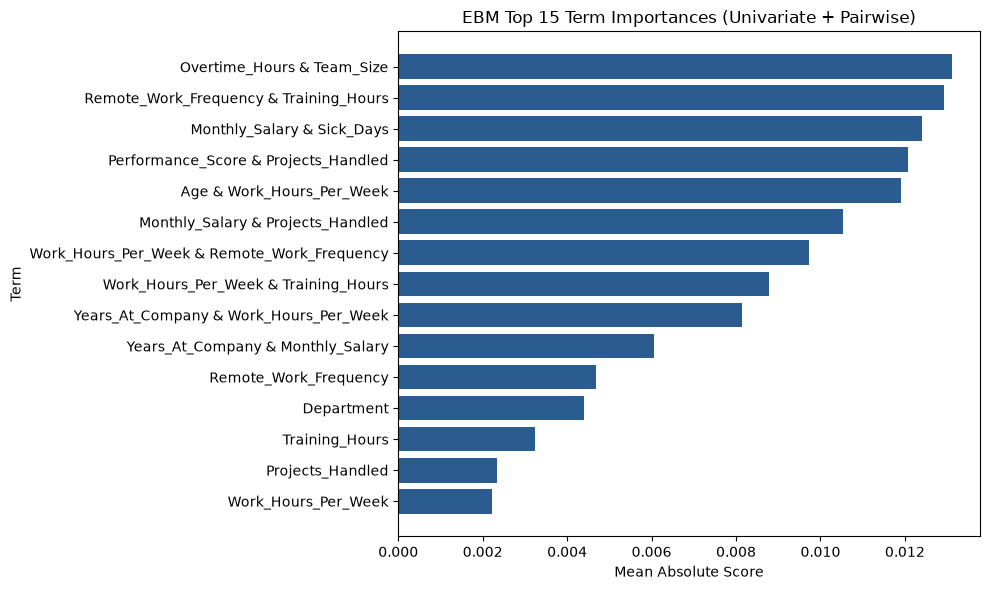

In [14]:
# Fit on the full development set for interpretability (glassbox explanations)
full_adapter = adapter_factory()
full_adapter.fit(X=dev_df[feature_cols], y=dev_df[target_col])

ebm_global = full_adapter._model.explain_global()
global_data = ebm_global.data()

importance_df = pd.DataFrame({
    "term": global_data["names"],
    "importance": global_data["scores"],
}).sort_values("importance", ascending=False).reset_index(drop=True)

print("Top 10 Terms by Global Importance (includes pairwise interactions):")
display(importance_df.head(10))

plt.figure(figsize=(10, 6))
top_terms = importance_df.head(15)
plt.barh(top_terms["term"][::-1], top_terms["importance"][::-1], color="#2b5c8f")
plt.xlabel("Mean Absolute Score")
plt.ylabel("Term")
plt.title("EBM Top 15 Term Importances (Univariate + Pairwise)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "figure_01_ebm_feature_importance.png", dpi=300)
plt.show()

## 15. Save Artifacts

Serialize OOF predictions (`oof_predictions.csv`), fold metrics (`fold_metrics.csv`), and model metadata.

In [15]:
oof_preds.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)
oof_preds.to_csv(RESULTS_DIR / "ebm_oof_predictions.csv", index=False)
fold_metrics_df.to_csv(RESULTS_DIR / "fold_metrics.csv", index=False)
fold_metrics_df.to_csv(RESULTS_DIR / "ebm_fold_metrics.csv", index=False)
importance_df.to_csv(RESULTS_DIR / "term_importances.csv", index=False)

with open(RESULTS_DIR / "summary_metrics.json", "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, indent=2)

with open(RESULTS_DIR / "ebm_summary_metrics.json", "w", encoding="utf-8") as f:
    json.dump(summary_metrics, f, indent=2)

model_metadata = full_adapter.save(RESULTS_DIR)
with open(RESULTS_DIR / "ebm_run_metadata.json", "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2, default=str)

print("All EBM artifacts successfully serialized to:", RESULTS_DIR)

All EBM artifacts successfully serialized to: /Users/hirukaliyanage/Employee_Resignation_Prediction/results/models/ebm


## 16. Summary & Readiness

The EBM pipeline has been executed with five-fold development OOF evaluation using the configured default hyperparameters.

- **Pooled Average Precision:** `0.098543`
- **Pooled ROC-AUC:** `0.493466`
- **Pooled Brier Score:** `0.090124`
- **Development Records:** 80,000 with complete OOF coverage
- **Formal Holdout:** quarantined; no holdout records were used

**Important:** the saved EBM evidence is a fixed/default-configuration run. The config defines a bounded search space, but a multi-candidate tuning run is not evidenced in this package. Therefore this result must not be described as the tuned EBM optimum.